# Chapter 4: Training Models — Test Field (Playground)

This is your independent playground to test concepts on real-world medical cost data.

---

### 📌 Python & Pandas Display Cheat Sheet
| Code | What it does |
| :--- | :--- |
| `df.head()` | Shows the first 5 rows in a clean table (or `df.head(10)` for 10 rows). |
| `df.info()` | Shows column names, data types, and checks for missing values. |
| `df.describe()` | Shows summary statistics (mean, min, max, std). |
| `df.columns` | Lists all column names (`age`, `sex`, `bmi`, `children`, `smoker`, `region`, `charges`). |


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Load dataset directly from raw online link
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

# Display the first few rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


---
## 🎯 Universal Plug-and-Play Linear Regression Test Cell

**How to use:**  
Just change the column names in lines 2 and 3 below (e.g., `"bmi"`, `"age"`, `"charges"`).  
Everything else (Normal Equation, Scikit-Learn, line predictions, and plot scaling) **updates automatically**!

=== Results for: AGE vs CHARGES ===
Intercept (theta_0): 3165.89 (Scikit-Learn: 3165.89)
Slope     (theta_1): 257.72 (Scikit-Learn: 257.72)


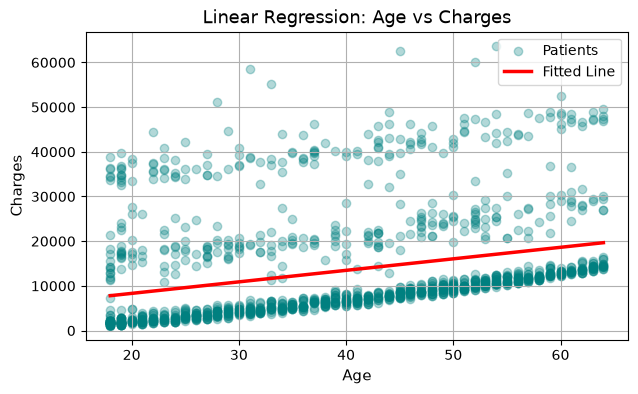

In [42]:
# ==========================================
# 1. CHOOSE WHAT COLUMNS YOU WANT TO TEST HERE
# ==========================================
feature_col = "age"       # X feature: try "age", "bmi", or "children"
target_col  = "charges"   # y target:  try "charges", or "bmi"

# ==========================================
# 2. EXTRACT 2D ARRAYS AUTOMATICALLY
# ==========================================
X = df[[feature_col]].values
y = df[[target_col]].values

# ==========================================
# 3. METHOD A: THE NORMAL EQUATION
# ==========================================
X_b = np.c_[np.ones((len(X), 1)), X]
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

# ==========================================
# 4. METHOD B: SCIKIT-LEARN LINEAR REGRESSION
# ==========================================
lin_reg = LinearRegression()
lin_reg.fit(X, y)

print(f"=== Results for: {feature_col.upper()} vs {target_col.upper()} ===")
print(f"Intercept (theta_0): {theta_best[0][0]:.2f} (Scikit-Learn: {lin_reg.intercept_[0]:.2f})")
print(f"Slope     (theta_1): {theta_best[1][0]:.2f} (Scikit-Learn: {lin_reg.coef_[0][0]:.2f})")

# ==========================================
# 5. DYNAMIC PREDICTION (Auto-adapts to min & max)
# ==========================================
# Automatically picks the smallest and largest values of whatever feature you chose!
X_new = np.array([[X.min()], [X.max()]])
y_predict = lin_reg.predict(X_new)

# ==========================================
# 6. AUTO-SCALED PLOT
# ==========================================
plt.figure(figsize=(7, 4))
plt.scatter(X, y, alpha=0.3, color="teal", label="Patients")
plt.plot(X_new, y_predict, "r-", linewidth=2.5, label="Fitted Line")
plt.xlabel(feature_col.capitalize(), fontsize=11)
plt.ylabel(target_col.capitalize(), fontsize=11)
plt.title(f"Linear Regression: {feature_col.capitalize()} vs {target_col.capitalize()}", fontsize=13)
plt.grid(True)
plt.legend()
plt.show()